# Programming assignment 2 - The lighted room

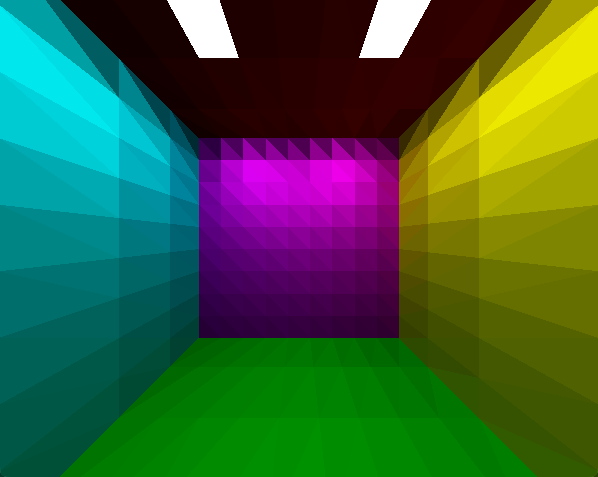

We will build on the code from the previous assignment.

## 1. New feature - reflection and emission [20 points]

In your previous code, there was one colour-related attribute associated to each element - a single (R,G,B) value.

We now wish there to be two attributes instead:
1. Emission
2. Reflection

These are intended to model physical attributes of the room, and will together determine the displayed color.

In [ ]:
class Light_Model_3d:
    def __init__(self, nodes, elements, emit, reflect):
        # adapt your code from before to include emit and reflect
        # you should edit the corresponding code for add_nodes, add_elements,
        # delete_nodes, and delete_elements

### a) Emission

Physically, emission is describing the *spectral emittance* (https://en.wikipedia.org/wiki/Radiant_exitance).

This is really a function of wavelength/frequency. An observer/camera will filter the light through long-/medium-/shortwave filters, to obtain $(L,M,S)$-values for the luminous exitance (https://en.wikipedia.org/wiki/Luminance), which may be later converted to $(R,G,B)$ values. See the lectures/assignment 8 for details.

*Aside: I have been deliberately vague about the units for $(L,M,S)$. This is because experiments suggest that $S$ does not contribute to our perception of brightness. Normalizing so that each take values in lux is therefore psychologically questionable. We follow the well-established practice of pretending this isn't important.*

We will simply give the emittance in terms of the associated three luminosities. 

For light directly reaching an observer this will not result in loss of information. As we will see below, it will for light that is reflected/refracted before reaching an observer, however for the sake of speed and clarity we will ignore this loss (as is the standard practice in computer graphics).


### b) Reflectivity

The reflectivity is also a function of wavelength, and in general also the angles of incidence and reflectance. Here we will assume that reflection is perfectly diffuse (https://en.wikipedia.org/wiki/Lambertian_reflectance). 

Suppose a light with spectral flux density $E(\lambda)$ impacts on a surface with diffuse reflectivity $R(\lambda)$. The reflected long-wave luminance will be
$$
\int_{\lambda} E(\lambda) R(\lambda) L(\lambda) d\lambda,
$$

and similarly for the medium- and short-wave luminances. If we define

$$
R_L = \frac{\int R(\lambda) L(\lambda) d\lambda}{\int L(\lambda) d\lambda},
$$

then the reflected long-wave luminance will be approximately $R_L E_L$, where $E_L$ is the incoming long-wave luminance. We will use this approximation, which is standard in computer graphics (the above physical justification is usually skipped in graphics books!). 

**Conclusion**: it will suffice to give reflectances between 0 and 1 for each of the long-, medium- and short-wave components of light.

## 2. A new geometry [30 points]

The room from the previous assignment had 12 elements - 2 triangles for each of the rooms 6 surfaces.

We will need to subdivide the surfaces into considerably more triangles if we wish to capture the subtleties of lighting.

It is your job to fill in the code that constructs the room; its geometry and colours.

### a) Model rectangles [10 points]

A good starting point is to write code that creates a model of a rectangle in a given position. Fill out the code below to achieve this. It will be a method of your 3d model class.

The nodes are to be located at regular positions in the rectangle - this part is provided for you. You will need to construct the elements. This should be done so that the triangular elements don't overlap, fill the rectangle, and such that every node is in at least one triangle (this prescription is telling you to do the 'obvious' thing: look at the walls in the picture of the room at the top of this document).

You will need to be careful with the ordering of the vertices in the elements - you want to ensure that the normal vectors point the way you want (see exercise 1 from assignment 8).

In [ ]:
# 10 points
@classmethod
def model_rect(cls,x0,x1,m,y0,y1,n,emit = np.array([0,0,0]),
                   reflect = np.array([0.5,0.5,0.5]),
                   vec=[0,0,0],axis=[0,0,1],angle=0):
    # divides a rectangle [x0,x1] x [y0,y1] located at z = 0 into an m x n grid
    # triangulates the grid in a regular manner
    # then translates and rotates the rectangle to the desired 3d position
    # the values of emit and reflect can be chosen
    x = np.linspace(x0,x1,m)
    y = np.linspace(y0,y1,n)
    XX, YY = np.meshgrid(x,y)
    Z = np.transpose(np.vstack((XX.reshape(n*m),YY.reshape(n*m))))
    c = np.zeros((m*n,1))
    nodes = np.hstack((Z, c))
    elements = ...

### b) Joining models [10 points]

The code above generates a model rectangle. You should then provide code to join together models to make a larger model.

In [ ]:
def add_model(self, other): # 10 points

### c) A model room [10 points]

You should now use the ingredients above to create the model for your room.

It should have 4 walls, a ceiling and a floor. The lights are in the ceiling. They should take up part, but not all, of the ceiling. They can be placed anywhere in the ceiling, but should not touch the walls.

Try to take $m$ and $n$ (from **2a) model_rect(...)**, determining the number of nodes/elements) as high as you can without making the program run impractically slowly. Try to aim for around $1000$ elements (or more if your code is sufficiently effective!).

In [1]:
# Create a model room, for 10 points

## 3. Radiosity - computing net luminances [30 points]

### a) Form factors [10 points]

To compute the net long-, medium- and shortwave luminances (and hence colour) of each element you will need to *assemble* the matrix of **form factors** 

$$
F_{ij} = \frac{1}{A_i} \int \int \frac{\cos(\theta_i)\cos(\theta_j)}{\pi r^2} dA_j dA_j,
$$

giving the proportion of the radiant flux (assumed diffuse) from element $j$ incident on element $j$. 

We want you to use the method indicated in the lectures/assignment 8 to approximate this integral simply for small triangular elements. You should integrate your code from assignment 8 into the 3d model.

The process of assembling the form factors will be the limiting factor on the number of elements your code can process in a reasonable time. My (non-optimised) solution handles around 1000 elements okay, much above that and it quickly becomes impractically slow. 

In [ ]:
def update_geometry(self): # 5 points
    # compute the normals and areas of each element

def update_form_factors(self): # 5 points
    # compute the form factor matrix

### b) Radiosities [20 points]

The radiosity (i.e. net emission, https://en.wikipedia.org/wiki/Radiosity_(radiometry)) $\hat{\Phi}_i$ of each element $i$ is given by solving the system

$$
\hat{\Phi}_i = \Phi_i + \sum_j R_i F_{ij} \hat{\Phi}_j,
$$

where $\Phi_i$ is the light emitted (not reflected) by element $i$ and $R_i$ is the reflectance of element $i$.

This should be solved for the $(L,M,S)$ components of the emission, i.e. each of $\hat{\Phi}_i,\Phi_i,R_i$ above is a vector with 3 elements. The form factors $F_{ij}$ are independent of wavelength, and are therefore the same for long-, medium- and short wavelength light.

You can solve the equation system either directly or by iterative methods (see the final lecture on lighting).

In [ ]:
def find_luminances(self,n) # 20 points

### c*) A warning 

It is safest to avoid high reflectances, a very reflective room might end up amplifying the emitted signals to such a point that it breaks the radiosity solver.

## 4. From LMS to RGB [15 points]

Having now computed the net luminances of each element, it only remains to convert to $(R,G,B)$ colour values in order to draw to the screen.

For more background, see the last question of assignment 8.

Remember that a pixel (R,G,B) value must be an integer between 0 and 255.

The simplest strategy will be to simply truncate the $(L,M,S)$ values to the nearest integer between 0 and 255. Note that if you adopt this strategy you will likely need to use light sources with emittance considerably greater than 255, otherwise your room will appear very dim.

*Greater than 255 what? 255 Watt? Lux would be a more suitable unit, at least for $L,M$, but see the comment in **1a** about units. Let's go for the SI-approved unit, 255 somethings...*

In practice, computer graphics programs often employ this strategy implicitly - in fact they will treat $(R,G,B)$-values as interchangeable with the luminances, and will imagine that the emittances/reflectivities are given in $(R,G,B)$-components, although this is not quite physical. This is relatively harmless as by the final question of assignment 8 there is only a linear transformation between the two (although see the concluding comment of that exercise!)

A further complication: the relationship between an integer $(R,G,B)$ value and the associated luminosities of the pixel on the computer screen is usually not linear (https://en.wikipedia.org/wiki/Gamma_correction). 

For a small bonus [5 points], try to implement a more physical conversion between $(L,M,S)$ and $(R,G,B)$, based on the last question of assignment 8, and a power-law gamma correction with $\gamma = 2.2$. The image below was rendered with gamma correction.

In [ ]:
def LMS_to_RGB(luminances): # 5 points
    return ...

def find_colors(self,n): # 10 points

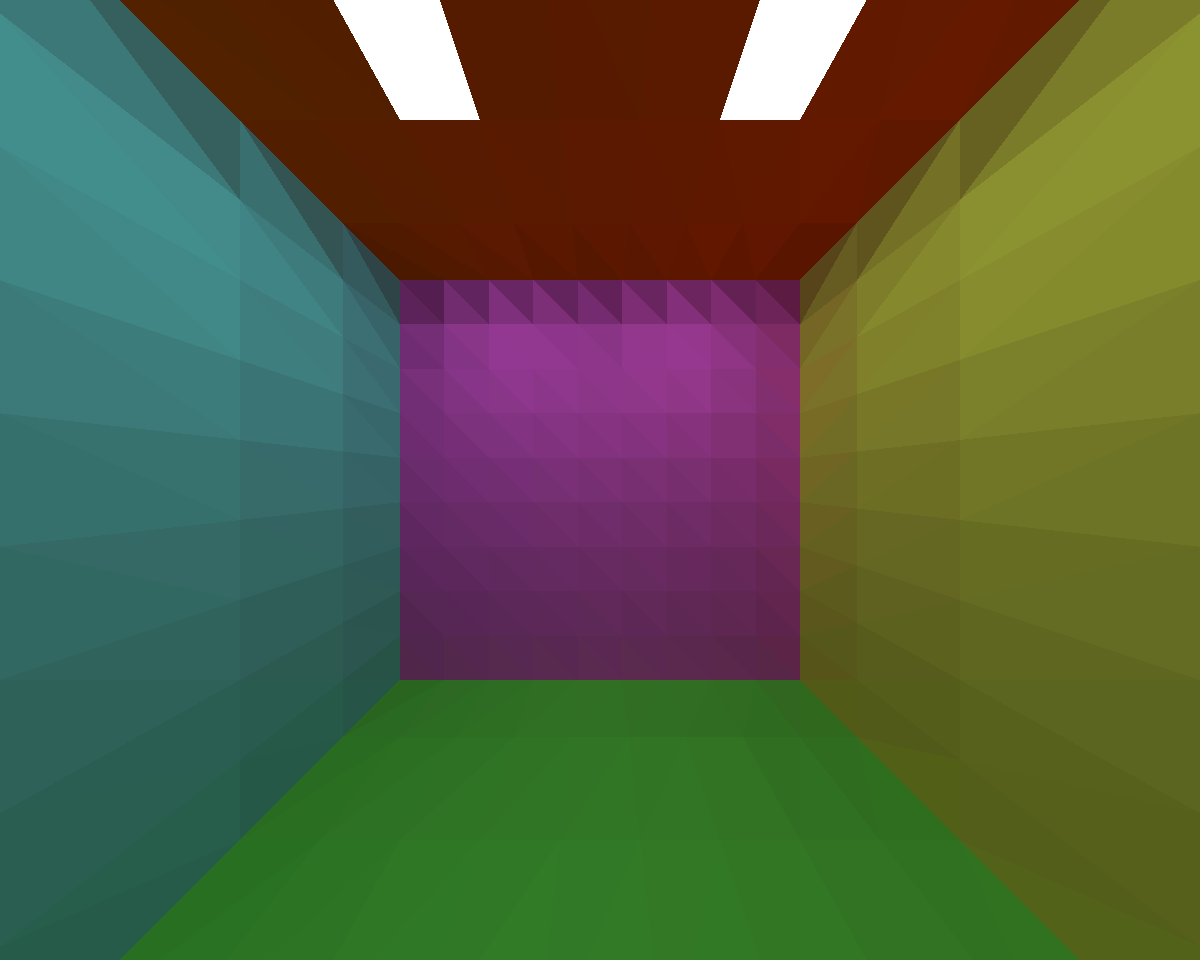

## 5. Application [5 points]

Finally, the application that runs the model. This can be more or less identical to the corresponding code from programming assignment 1.

In [ ]:
# Rotations about different axes
# You can choose different rotation increments if you want
qx = quaternions.Quaternion.from_rotation(...)
qy = quaternions.Quaternion.from_rotation(...)
qz = quaternions.Quaternion.from_rotation(np.array(...)

# Insert focal length here
f = 100

# Draw to the screen
# Z is the model created in exercise 2.
Z.draw(f, width, height)
                                          
window = pyglet.window.Window(width=width,height=height,resizable=True)

@window.event
def on_draw():
    window.clear()
    Z.batch.draw()    
    
@window.event 
def on_key_press(symbol, modifiers): # 10 points
    # fill in
    
# If you prefer you can use mouse input instead, or a mixture of keys and mouse
    
pyglet.app.run()